# Airbnb NYC 2019 — Exploratory Data Analysis & Data Wrangling

**Project objective:** Analyze Airbnb listings in New York City to understand pricing patterns across neighborhoods and room types, investigate the relationship between reviews and price, and examine host listing distributions.

**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn

**Workflow:** Data acquisition → Data inspection → Data cleaning → Exploratory Data Analysis → Findings and recommendations

In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries are ready!")

All libraries are ready!


In [62]:
import pandas as pd

df = pd.read_csv("/AB_NYC_2019.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (48895, 16)


## 1. Data Cleaning

The dataset was inspected to identify missing values and prepare it for analysis. The cleaning process includes converting review dates to datetime format, filling missing monthly review counts with zero, removing listings with missing critical data, and identifying extreme prices using the IQR method.

In [63]:
# Create a copy of the original dataset
df_clean = df.copy()

# Convert last_review to datetime
df_clean["last_review"] = pd.to_datetime(
    df_clean["last_review"], errors="coerce"
)

# Fill missing monthly review counts with 0
df_clean["reviews_per_month"] = (
    df_clean["reviews_per_month"].fillna(0)
)

# Remove listings missing critical data
df_clean = df_clean.dropna(
    subset=["price", "neighbourhood"]
).copy()

# Calculate IQR boundaries for price
Q1 = df_clean["price"].quantile(0.25)
Q3 = df_clean["price"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Remove extreme price outliers
df_clean = df_clean[
    (df_clean["price"] >= lower_bound) &
    (df_clean["price"] <= upper_bound)
].copy()

# Verify the cleaning results
print("Original listings:", len(df))
print("Cleaned listings:", len(df_clean))
print("Missing prices:", df_clean["price"].isna().sum())
print("Missing neighborhoods:",
      df_clean["neighbourhood"].isna().sum())
print("Missing monthly reviews:",
      df_clean["reviews_per_month"].isna().sum())
print("Missing review dates:",
      df_clean["last_review"].isna().sum())
print("Price IQR boundaries:", lower_bound, upper_bound)

Original listings: 48895
Cleaned listings: 45923
Missing prices: 0
Missing neighborhoods: 0
Missing monthly reviews: 0
Missing review dates: 9012
Price IQR boundaries: -90.0 334.0


## 2. Exploratory Data Analysis

### 2.1 Which neighborhoods have the highest average Airbnb prices?

This analysis groups listings by neighborhood and calculates the average nightly price to identify the most expensive neighborhoods in the cleaned dataset.

In [64]:
# Calculate average price by neighborhood
neighborhood_prices = (
    df_clean.groupby("neighbourhood")["price"]
    .mean()
    .sort_values(ascending=False)
)

# Select the 10 neighborhoods with the highest averages
top_10_neighborhoods = neighborhood_prices.head(10)

display(top_10_neighborhoods)

,price
neighbourhood,
Willowbrook,249.000000
Neponsit,237.000000
Breezy Point,213.333333
Tribeca,212.495327
NoHo,205.290909
West Village,193.118644
Flatiron District,188.090909
Financial District,183.973926
Midtown,181.082168


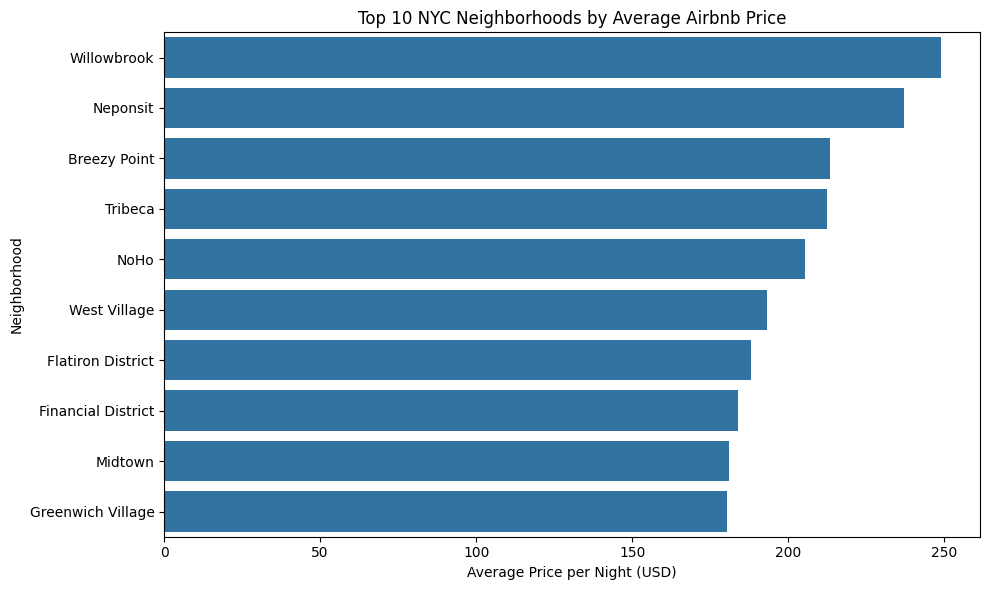

In [65]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_10_neighborhoods.values,
    y=top_10_neighborhoods.index
)

plt.title("Top 10 NYC Neighborhoods by Average Airbnb Price")
plt.xlabel("Average Price per Night (USD)")
plt.ylabel("Neighborhood")

plt.tight_layout()
plt.show()

### 2.2 How do prices vary by room type?

This analysis compares the average nightly price across Airbnb room types in New York City to identify which accommodation type is the most expensive and which is the most affordable.**bold text**

In [66]:
# Calculate average price for each room type
room_prices = (
    df_clean.groupby("room_type")["price"]
    .mean()
    .sort_values(ascending=False)
)

display(room_prices.round(2))

,price
room_type,
Entire home/apt,162.53
Private room,79.02
Shared room,59.29


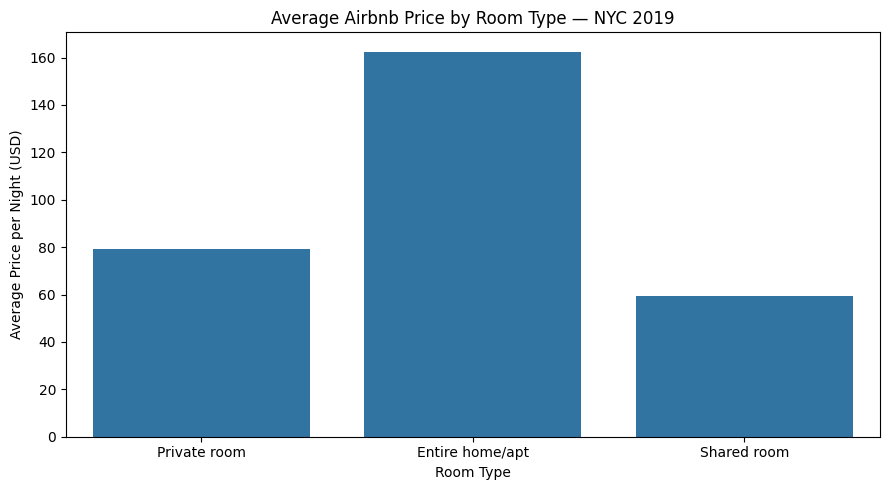

In [67]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df_clean,
    x="room_type",
    y="price",
    estimator="mean",
    errorbar=None
)

plt.title("Average Airbnb Price by Room Type — NYC 2019")
plt.xlabel("Room Type")
plt.ylabel("Average Price per Night (USD)")

plt.tight_layout()
plt.show()

### 2.3 Is there a relationship between the number of reviews and price?

This analysis investigates the relationship between the number of reviews received by an Airbnb listing and its nightly price using a scatter plot and Pearson correlation.

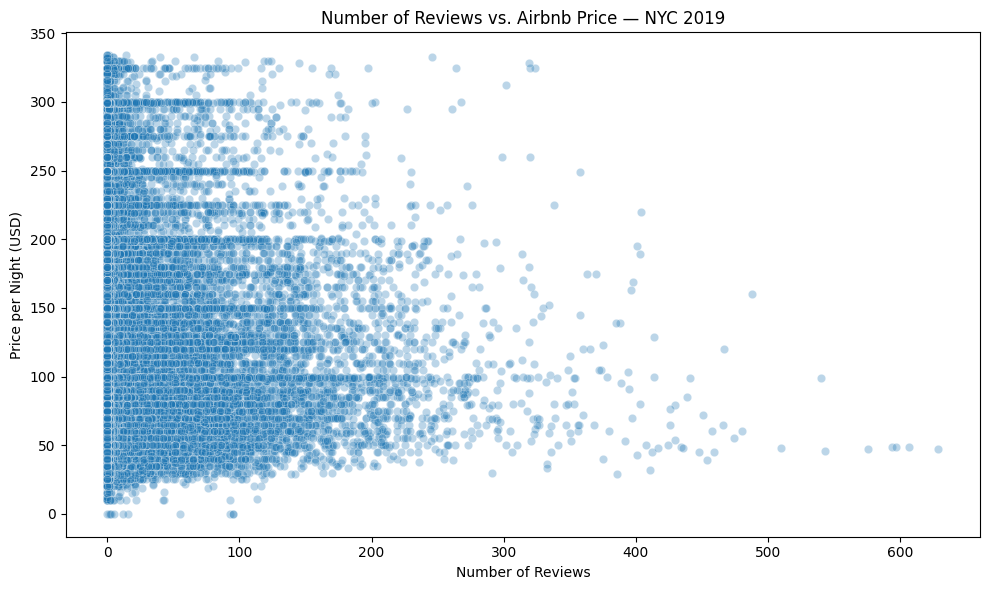

In [68]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x="number_of_reviews",
    y="price",
    alpha=0.3
)

plt.title("Number of Reviews vs. Airbnb Price — NYC 2019")
plt.xlabel("Number of Reviews")
plt.ylabel("Price per Night (USD)")

plt.tight_layout()
plt.show()

In [69]:
correlation = df_clean[
    ["number_of_reviews", "price"]
].corr().iloc[0, 1]

print("Pearson correlation:", round(correlation, 3))

Pearson correlation: -0.028


### 2.4 What is the distribution of listings by host?

This analysis examines how Airbnb listings are distributed among hosts and identifies the hosts managing the largest number of listings.

In [70]:
# Count listings for each host
host_listings = (
    df_clean.groupby(["host_id", "host_name"])
    .size()
    .reset_index(name="listing_count")
)

# Select the 10 hosts with the most listings
top_hosts = host_listings.sort_values(
    "listing_count", ascending=False
).head(10)

display(top_hosts)

,host_id,host_name,listing_count
32882,219517861,Sonder (NYC),272
27960,107434423,Blueground,180
29550,137358866,Kazuya,103
18575,30283594,Kara,95
12119,12243051,Sonder,95
24394,61391963,Corporate Housing,91
13674,16098958,Jeremy & Laura,90
16222,22541573,Ken,87
9248,7503643,Vida,52
2901,1475015,Mike,52


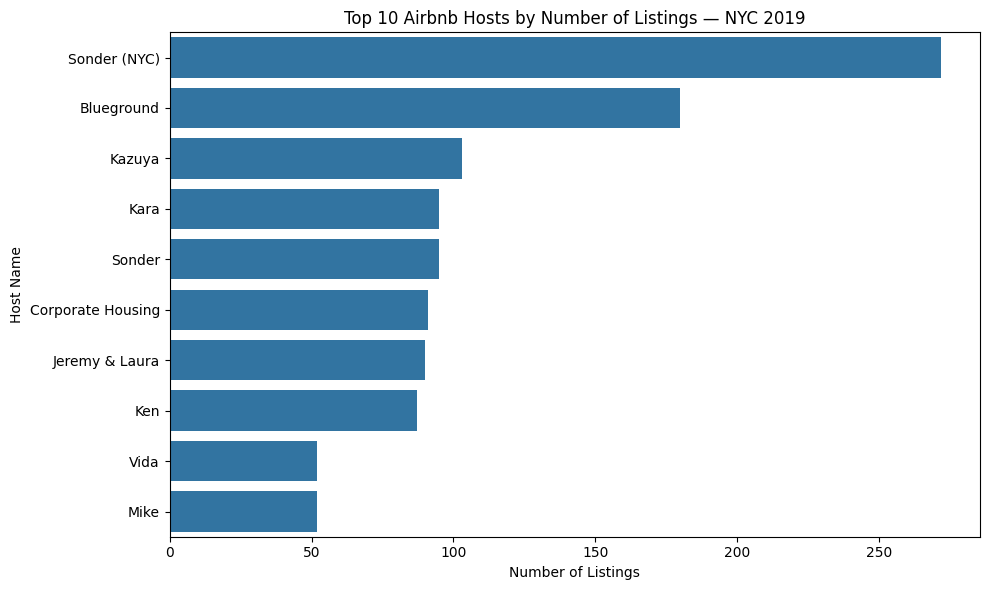

In [71]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_hosts,
    x="listing_count",
    y="host_name"
)

plt.title("Top 10 Airbnb Hosts by Number of Listings — NYC 2019")
plt.xlabel("Number of Listings")
plt.ylabel("Host Name")

plt.tight_layout()
plt.show()

In [72]:
# Count listings for each host
host_listings = (
    df_clean.groupby(["host_id", "host_name"])
    .size()
    .reset_index(name="listing_count")
)

# Find the 10 hosts with the most listings
top_hosts = host_listings.sort_values(
    "listing_count", ascending=False
).head(10)

display(top_hosts)

,host_id,host_name,listing_count
32882,219517861,Sonder (NYC),272
27960,107434423,Blueground,180
29550,137358866,Kazuya,103
18575,30283594,Kara,95
12119,12243051,Sonder,95
24394,61391963,Corporate Housing,91
13674,16098958,Jeremy & Laura,90
16222,22541573,Ken,87
9248,7503643,Vida,52
2901,1475015,Mike,52


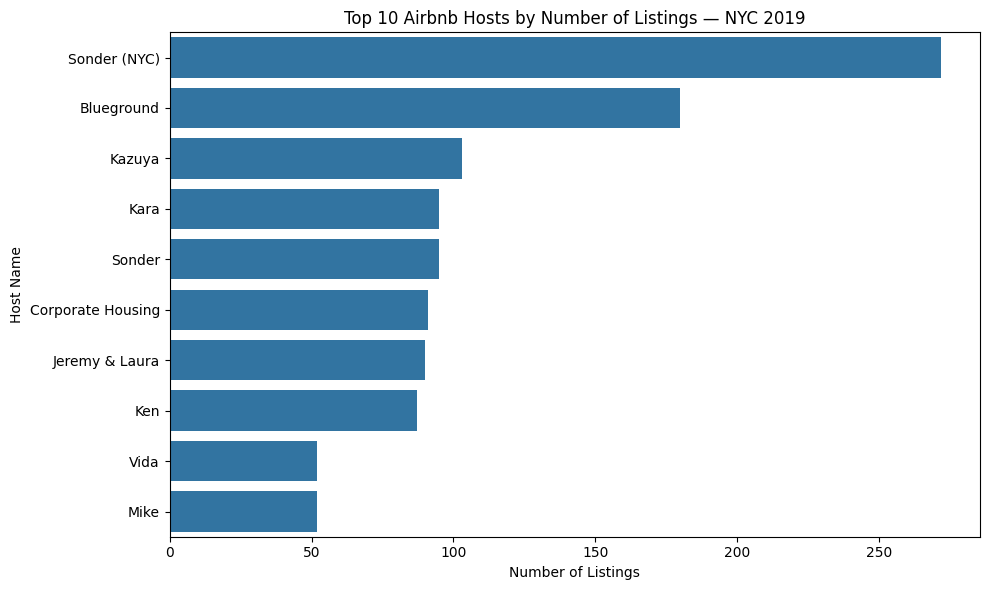

In [73]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_hosts,
    x="listing_count",
    y="host_name"
)

plt.title("Top 10 Airbnb Hosts by Number of Listings — NYC 2019")
plt.xlabel("Number of Listings")
plt.ylabel("Host Name")

plt.tight_layout()
plt.show()

## 3. Conclusion

This project explored Airbnb listings in New York City in 2019 using Python, Pandas, Matplotlib, and Seaborn. The analysis examined average prices across neighborhoods, price differences between room types, the relationship between review counts and prices, and the distribution of listings among hosts.

The data-cleaning process converted review dates to datetime format, filled missing monthly review counts with zero, removed listings with missing critical data, and applied the IQR method to identify and remove extreme prices.

The findings help describe Airbnb pricing patterns and host activity across NYC. The results should be interpreted in the context of the cleaning decisions, particularly the removal of price outliers.